# Quantum Machine Learning: Encodings, Variational Classifiers, Quantum Kernels and Their Limits

> **Who is this for:** ML engineers who know classical machine learning and have done [01_quantum_computing_basics.ipynb](01_quantum_computing_basics.ipynb). You want a clear, honest picture of quantum machine learning (QML), with code you can run.
>
> **What you will learn:**
> - what QML is: the **four combinations** of classical/quantum data and classical/quantum algorithms
> - **data encoding**: basis, angle and amplitude encoding, and **data re-uploading**
> - **parameterised (variational) quantum circuits** as "quantum neural networks"
> - the **parameter-shift rule** for exact gradients (implemented and checked against finite differences)
> - **train a variational classifier** on a toy 2-D dataset (make_moons) and plot its decision boundary
> - **quantum kernels**: compute a fidelity kernel matrix and feed it to `SVC(kernel="precomputed")`, compared with an RBF SVM
> - **hybrid** quantum-classical models, **quantum reinforcement learning** and **quantum GANs** (short, conceptual)
> - the **limits**: barren plateaus (a small experiment), noise, the data-loading bottleneck, and **dequantization**. The honest takeaway is that classical methods usually win today
>
> **Prerequisites:** [01_quantum_computing_basics.ipynb](01_quantum_computing_basics.ipynb), [02_quantum_algorithms.ipynb](02_quantum_algorithms.ipynb) (section 7, variational algorithms), [your first ML model](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb), [SVMs](../03_Machine_Learning/01_supervised/05_svm.ipynb) (kernels), [neural network fundamentals](../05_Deep_Learning/01_neural_network_fundamentals.ipynb) (gradient descent), [linear algebra](../14_Mathematics/01_linear_algebra.ipynb).
>
> **Time needed:** about 2-3 hours. The notebook runs in about half a minute.
>
> **Runs on:** CPU, no API key, no internet. numpy, scikit-learn, scipy and matplotlib.

## 0. Setup

We reuse the small simulator from notebook 01. For training we also need a **batched** version that simulates many data points at once (one state per row), which makes training fast.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)

In [2]:
# ---- The tiny statevector simulator from notebook 01 (same code, in one cell) ----
from collections import Counter

# Single-qubit gates (2x2 matrices)
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
S = np.array([[1, 0], [0, 1j]], dtype=complex)
T = np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]], dtype=complex)

def RX(t): return np.array([[np.cos(t/2), -1j*np.sin(t/2)], [-1j*np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RY(t): return np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RZ(t): return np.array([[np.exp(-1j*t/2), 0], [0, np.exp(1j*t/2)]], dtype=complex)

# Two-qubit gates (4x4). The first qubit listed is the control.
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)
CZ = np.diag([1, 1, 1, -1]).astype(complex)

def apply_gate(psi, U, qubits, n):
    """Apply matrix U to the listed qubits of an n-qubit state psi.
    Qubit 0 is the LEFT-most bit of a bitstring like '011'."""
    k = len(qubits)
    psi = psi.reshape([2] * n)
    U = U.reshape([2] * (2 * k))
    psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(qubits)))
    psi = np.moveaxis(psi, list(range(k)), list(qubits))
    return psi.reshape(-1)

class QSim:
    """A tiny statevector simulator. Methods return self, so calls can be chained."""
    def __init__(self, n):
        self.n = n
        self.psi = np.zeros(2 ** n, dtype=complex)
        self.psi[0] = 1.0                      # start in |00...0>
    def gate(self, U, *qubits):
        self.psi = apply_gate(self.psi, U, qubits, self.n); return self
    def x(self, q):  return self.gate(X, q)
    def y(self, q):  return self.gate(Y, q)
    def z(self, q):  return self.gate(Z, q)
    def h(self, q):  return self.gate(H, q)
    def s(self, q):  return self.gate(S, q)
    def t(self, q):  return self.gate(T, q)
    def rx(self, th, q): return self.gate(RX(th), q)
    def ry(self, th, q): return self.gate(RY(th), q)
    def rz(self, th, q): return self.gate(RZ(th), q)
    def cx(self, c, t): return self.gate(CNOT, c, t)
    def cz(self, a, b): return self.gate(CZ, a, b)
    def probs(self):
        return np.abs(self.psi) ** 2
    def measure(self, shots=1000, seed=0):
        """Sample bitstrings like a real device would. Returns a Counter."""
        rng = np.random.default_rng(seed)
        p = self.probs(); p = p / p.sum()
        idx = rng.choice(len(p), size=shots, p=p)
        return Counter(format(i, f"0{self.n}b") for i in idx)

def bitstrings(n):
    return [format(i, f"0{n}b") for i in range(2 ** n)]

def plot_counts(counts, title="", ax=None):
    """Bar chart of measurement counts, with every bitstring on the x-axis."""
    n = len(next(iter(counts)))
    labels = bitstrings(n)
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(labels, [counts.get(b, 0) for b in labels], color="tab:blue")
    ax.set_title(title); ax.set_ylabel("counts")
    ax.tick_params(axis="x", rotation=90 if n > 3 else 0)
    plt.tight_layout()
    return ax

def show_state(psi, tol=1e-9):
    """Print the non-zero amplitudes of a state in ket notation."""
    n = int(np.log2(len(psi)))
    for i, a in enumerate(psi):
        if abs(a) > tol:
            print(f"  |{format(i, f'0{n}b')}>  amplitude {a.real:+.3f}{a.imag:+.3f}j   probability {abs(a)**2:.3f}")

print("Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state")

Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state


In [3]:
# ---- Batched helpers: simulate B states at once, array shape (B, 2**n) ----
def rot(axis, theta):
    """Rotation matrices for an array of angles: shape (B, 2, 2) (or (2, 2) for one angle)."""
    t = np.asarray(theta, dtype=float); c, s = np.cos(t / 2), np.sin(t / 2)
    U = np.zeros(t.shape + (2, 2), dtype=complex)
    if axis == "x":   U[..., 0, 0] = c; U[..., 0, 1] = -1j * s; U[..., 1, 0] = -1j * s; U[..., 1, 1] = c
    elif axis == "y": U[..., 0, 0] = c; U[..., 0, 1] = -s;      U[..., 1, 0] = s;       U[..., 1, 1] = c
    else:             U[..., 0, 0] = np.exp(-1j * t / 2);       U[..., 1, 1] = np.exp(1j * t / 2)
    return U

def apply_1q_batch(psi, U, q, n):
    """Apply a 1-qubit gate (one matrix, or one matrix per row) to qubit q of every state."""
    B = psi.shape[0]
    p = psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))           # split out the axis of qubit q
    U = np.broadcast_to(U, (B, 2, 2))
    out = np.empty_like(p)
    out[:, :, 0, :] = U[:, 0, 0, None, None] * p[:, :, 0, :] + U[:, 0, 1, None, None] * p[:, :, 1, :]
    out[:, :, 1, :] = U[:, 1, 0, None, None] * p[:, :, 0, :] + U[:, 1, 1, None, None] * p[:, :, 1, :]
    return out.reshape(B, -1)

def cnot_batch(psi, c, t, n):
    idx = np.arange(2 ** n); ctrl = (idx >> (n - 1 - c)) & 1
    return psi[:, np.where(ctrl == 1, idx ^ (1 << (n - 1 - t)), idx)]   # CNOT just permutes amplitudes

def z_signs(n, qubits):
    """+1/-1 eigenvalues of Z on the listed qubits (a product of Z's) for every basis state."""
    idx = np.arange(2 ** n); s = np.ones(2 ** n)
    for q in qubits: s = s * (1 - 2 * ((idx >> (n - 1 - q)) & 1))
    return s

def zero_states(B, n):
    psi = np.zeros((B, 2 ** n), dtype=complex); psi[:, 0] = 1; return psi

# quick test against the single-state simulator
xs = np.array([0.3, 1.2])
psi = cnot_batch(apply_1q_batch(zero_states(2, 2), rot("y", xs), 0, 2), 0, 1, 2)
print("batched == QSim:", np.allclose(psi[1], QSim(2).ry(1.2, 0).cx(0, 1).psi))

batched == QSim: True


## 1. What is quantum machine learning?

**What it is.** **Quantum machine learning (QML)** is the research area where quantum computing and machine learning meet. "Quantum" can describe the **data** (where it comes from) or the **algorithm** (what device processes it). This gives four combinations (the naming follows Schuld and Petruccione):

| | Classical algorithm (CPU/GPU) | Quantum algorithm (quantum device) |
|---|---|---|
| **Classical data** (images, text, tables) | **CC**: ordinary ML. Also "quantum-inspired" classical algorithms | **CQ**: run classical data through a quantum circuit (variational classifiers, quantum kernels). *Most QML papers, and this notebook* |
| **Quantum data** (states from a quantum sensor, experiment or simulation) | **QC**: classical ML that *helps* quantum computers (decoders for error correction, calibration, reading noisy measurements). See notebook 04 | **QQ**: a quantum computer that processes quantum states directly (for example learning properties of a quantum system). Strong theoretical results exist here |

**Simple analogy.** Classical data on a quantum computer is like translating a novel into a language with a hugely rich grammar, processing it there, and translating back. The rich grammar might help, but the translation in and out is slow and lossy. Quantum data is already "in that language", which is why the QQ corner is where many researchers expect the clearest advantages.

**How a typical CQ model works.**

```mermaid
flowchart LR
    x[classical input x] --> E[Encoding circuit<br/>angles from x]
    E --> W[Trainable circuit<br/>angles theta]
    W --> M[Measure many shots<br/>expectation value]
    M --> L[Loss on a CPU]
    L --> O[Optimiser<br/>parameter-shift gradients]
    O -->|update theta| W
```

## 2. Data encoding: getting numbers into qubits

**What it is.** Before a quantum circuit can learn from data, each input $x$ must be turned into a quantum state $\lvert\phi(x)\rangle$. This step is called **encoding** (or **embedding**, or **feature map**). It matters a lot: the encoding largely decides which functions the model can represent.

| Encoding | How | Qubits for d features | Circuit cost | Notes |
|---|---|---|---|---|
| **Basis** | a bitstring becomes a basis state: `101` → $\lvert101\rangle$ | d (one per bit) | a few X gates | only for binary data |
| **Angle** | each feature is a rotation angle: RY($x_i$) on qubit i | d | d gates | cheap; the model sees $\cos$ and $\sin$ of the features |
| **Amplitude** | a normalised vector of $2^n$ numbers becomes the $2^n$ amplitudes | $\log_2 d$ | in general about $d$ gates (or more) | very compact, but loading is expensive: the **data-loading bottleneck** |
| **Re-uploading** | repeat an angle encoding several times, with trainable layers in between | d (or fewer) | grows with the number of repeats | makes the model much more expressive (section 5) |

**Simple analogy.** Basis encoding is writing a number with light switches (on/off). Angle encoding is setting dimmer knobs. Amplitude encoding is like squeezing a whole spreadsheet column into the shape of one sound wave: very compact, but someone must shape the wave carefully, and that takes time.

In [4]:
# Basis encoding: the bitstring 101 -> X on qubits 0 and 2
print("basis encoding of '101':"); show_state(QSim(3).x(0).x(2).psi)

# Angle encoding: x = (0.5, 2.0) -> RY(0.5) on qubit 0, RY(2.0) on qubit 1
print("\nangle encoding of (0.5, 2.0):"); show_state(QSim(2).ry(0.5, 0).ry(2.0, 1).psi)

# Amplitude encoding: 4 numbers -> 2 qubits (after normalising to length 1)
x4 = np.array([3.0, 1.0, 0.0, 2.0])
amp_state = x4 / np.linalg.norm(x4)
print("\namplitude encoding of", x4, "-> 2 qubits")
show_state(amp_state.astype(complex))
print("measurement probabilities are x_i^2 / sum(x^2):", np.round(x4**2 / (x4**2).sum(), 3))

basis encoding of '101':
  |101>  amplitude +1.000+0.000j   probability 1.000

angle encoding of (0.5, 2.0):
  |00>  amplitude +0.524+0.000j   probability 0.274
  |01>  amplitude +0.815+0.000j   probability 0.665
  |10>  amplitude +0.134+0.000j   probability 0.018
  |11>  amplitude +0.208+0.000j   probability 0.043

amplitude encoding of [3. 1. 0. 2.] -> 2 qubits
  |00>  amplitude +0.802+0.000j   probability 0.643
  |01>  amplitude +0.267+0.000j   probability 0.071
  |11>  amplitude +0.535+0.000j   probability 0.286
measurement probabilities are x_i^2 / sum(x^2): [0.643 0.071 0.    0.286]


**What just happened?** Amplitude encoding stored 4 numbers in only 2 qubits (in general $2^n$ numbers in $n$ qubits). But (1) preparing an arbitrary amplitude state usually needs a circuit with about as many gates as there are numbers, and (2) you cannot read the amplitudes back out cheaply. The exponential compactness does not come for free; section 10 returns to this.

## 3. Variational circuits as "quantum neural networks"

**What it is.** A **variational quantum circuit** (also called a **parameterised quantum circuit**, PQC, or loosely a **quantum neural network**, QNN) is: an encoding block, then trainable rotation gates with angles $\theta$, then a measurement. The model output is an **expectation value**, the average of a measured quantity, for example $\langle Z\rangle$ = P(0) − P(1), which lies between −1 and +1.

**Simple analogy.** A neural network is a long chain of adjustable knobs (weights) and bends (activations). A PQC is a chain of adjustable *rotations* of a high-dimensional arrow (the state). Training turns the knobs in both cases.

| | Classical neural network | Variational quantum circuit |
|---|---|---|
| Parameters | weights and biases | rotation angles |
| Non-linearity | activation functions (ReLU, ...) | none inside (gates are linear); comes from the encoding ($\cos$, $\sin$ of x) and from measurement |
| Output | any number | an expectation value in [−1, 1], estimated from shots |
| Gradients | backpropagation (cheap) | parameter-shift rule: 2 extra circuit runs **per parameter** |
| Scale today | billions of parameters | tens to a few thousand parameters |

Our classifier for 2-D points uses 2 qubits and 3 layers. Each layer re-uploads the data (RY($x_0$), RY($x_1$)), then applies trainable RY and RZ rotations and a CNOT:

```
q0: -RY(x0)-RY(w0)-RZ(w2)-o-   (x3 layers)  ... measure <Z> on q0
q1: -RY(x1)-RY(w1)-RZ(w3)-X-
```

In [5]:
N_LAYERS = 3

def classifier_expval(X, w):
    """Variational classifier. X: (B, 2) inputs, w: (N_LAYERS, 4) angles. Returns <Z0> for each row."""
    psi = zero_states(len(X), 2)
    for l in range(N_LAYERS):
        psi = apply_1q_batch(psi, rot("y", X[:, 0]), 0, 2)    # data re-uploading
        psi = apply_1q_batch(psi, rot("y", X[:, 1]), 1, 2)
        psi = apply_1q_batch(psi, rot("y", w[l, 0]), 0, 2)     # trainable rotations
        psi = apply_1q_batch(psi, rot("y", w[l, 1]), 1, 2)
        psi = apply_1q_batch(psi, rot("z", w[l, 2]), 0, 2)
        psi = apply_1q_batch(psi, rot("z", w[l, 3]), 1, 2)
        psi = cnot_batch(psi, 0, 1, 2)                         # entangling gate
    return (np.abs(psi) ** 2) @ z_signs(2, [0])               # <Z> on qubit 0

w_demo = rng.normal(0, 1, (N_LAYERS, 4))
print("outputs for 3 random inputs:", classifier_expval(rng.normal(size=(3, 2)), w_demo))

outputs for 3 random inputs: [-0.2735 -0.072  -0.1256]


## 4. The parameter-shift rule: exact gradients from two circuit runs

**What it is.** On real hardware we cannot backpropagate through the quantum state, because we cannot see it. The **parameter-shift rule** gives the *exact* derivative of an expectation value with respect to a rotation angle, using two more runs of the same circuit with that angle shifted by $\pm\pi/2$:

$$\frac{\partial \langle O\rangle}{\partial\theta} = \frac{\langle O\rangle(\theta+\tfrac{\pi}{2}) - \langle O\rangle(\theta-\tfrac{\pi}{2})}{2}$$

It holds for gates of the form $e^{-i\theta P/2}$ where P is a Pauli matrix (RX, RY, RZ). (Mitarai et al. 2018; Schuld et al. 2019.)

**Simple analogy.** To find the slope of a hill under your feet, you could take a tiny step left and right (finite differences). On a noisy quantum device a tiny step is lost in the shot noise. The parameter-shift rule says: for these special "sine-wave" hills, two *big* steps of a quarter-turn give the exact slope, so the signal is large compared with the noise.

**How it works (why it is exact).** As a function of one angle, the expectation value is a pure sine wave: $f(\theta) = a + b\cos\theta + c\sin\theta$. For a sine wave, the difference of the values a quarter period on either side equals twice the slope.

**When to use it / when not.** Use it on hardware and for exact analytic gradients. On a simulator, backpropagation (used by PennyLane's `default.qubit` with autograd, for example) is much faster. The cost on hardware is 2 runs per parameter per data point, so models with many parameters get expensive.

In [6]:
# 1-qubit check: <Z> after RY(theta)|0> is cos(theta), so the true derivative is -sin(theta)
f1 = lambda th: np.cos(th)          # what the circuit computes (checked below)
th = 0.9
psi = QSim(1).ry(th, 0).psi
print("circuit <Z> =", round(abs(psi[0])**2 - abs(psi[1])**2, 6), "  cos(theta) =", round(np.cos(th), 6))
ps = (f1(th + np.pi / 2) - f1(th - np.pi / 2)) / 2
print(f"parameter shift {ps:.6f}   exact -sin(theta) {-np.sin(th):.6f}")

circuit <Z> = 0.62161   cos(theta) = 0.62161
parameter shift -0.783327   exact -sin(theta) -0.783327


In [7]:
def param_shift_grad(f, w):
    """Gradient of f(w) (an array over the batch) with respect to every entry of w.
    Returns an array of shape w.shape + (batch,)."""
    grads = []
    for k in np.ndindex(w.shape):
        wp, wm = w.copy(), w.copy()
        wp[k] += np.pi / 2; wm[k] -= np.pi / 2
        grads.append((f(wp) - f(wm)) / 2)
    return np.array(grads).reshape(w.shape + (-1,))

def finite_diff_grad(f, w, eps=1e-5):
    grads = []
    for k in np.ndindex(w.shape):
        wp, wm = w.copy(), w.copy()
        wp[k] += eps; wm[k] -= eps
        grads.append((f(wp) - f(wm)) / (2 * eps))
    return np.array(grads).reshape(w.shape + (-1,))

X_check = rng.normal(size=(5, 2))
f = lambda w: classifier_expval(X_check, w)
g_ps, g_fd = param_shift_grad(f, w_demo), finite_diff_grad(f, w_demo)
print("first 4 gradient entries for data point 0:")
print("  parameter shift   :", g_ps[0, :, 0])
print("  finite difference :", g_fd[0, :, 0])
print("max difference over all 12 parameters x 5 points:", np.abs(g_ps - g_fd).max())

first 4 gradient entries for data point 0:
  parameter shift   : [-0.2579 -0.5295  0.344   0.3487]
  finite difference : [-0.2579 -0.5295  0.344   0.3487]
max difference over all 12 parameters x 5 points: 3.483618775390607e-11


In [8]:
# Why big shifts matter on hardware: estimate the 1-qubit gradient from 1000 shots each
def z_from_shots(theta, shots, rng):
    p0 = np.cos(theta / 2) ** 2
    zeros = rng.binomial(shots, p0)
    return (2 * zeros - shots) / shots

trials = 2000
ps_est = [(z_from_shots(th + np.pi/2, 1000, rng) - z_from_shots(th - np.pi/2, 1000, rng)) / 2 for _ in range(trials)]
fd_est = [(z_from_shots(th + 0.01, 1000, rng) - z_from_shots(th - 0.01, 1000, rng)) / 0.02 for _ in range(trials)]
print(f"true gradient {-np.sin(th):.3f}")
print(f"parameter shift with shots: mean {np.mean(ps_est):.3f}, spread (std) {np.std(ps_est):.3f}")
print(f"finite diff (eps=0.01) with shots: mean {np.mean(fd_est):.3f}, spread (std) {np.std(fd_est):.3f}")

true gradient -0.783
parameter shift with shots: mean -0.783, spread (std) 0.014
finite diff (eps=0.01) with shots: mean -0.787, spread (std) 1.767


**What just happened?** On a perfect simulator both methods agree (differences around $10^{-10}$). With 1000 shots per circuit, the parameter-shift estimate has a small spread, while the finite-difference estimate is almost pure noise, because dividing a small noisy difference by 0.02 blows the noise up about 70 times.

## 5. Data re-uploading: why repeating the encoding helps

**What it is.** **Data re-uploading** (Pérez-Salinas et al., 2020) feeds the same input into the circuit several times, with trainable gates in between. Schuld, Sweke and Meyer (2021) showed that such a model computes a **Fourier series** in $x$ (a sum of sines and cosines), and **the number of repeats decides the highest frequency** it can represent. One RY($x$) encoding gives only frequency 1, so the model can only draw $a + b\cos x + c\sin x$.

**Simple analogy.** A music box with one note can only play one pitch. Each re-upload adds a higher note to the box, so it can play richer tunes.

**Tiny demo.** A 1-qubit model with L re-uploads tries to fit a target that contains frequency 2: $g(x) = 0.5\sin(2x) + 0.4\cos x$.

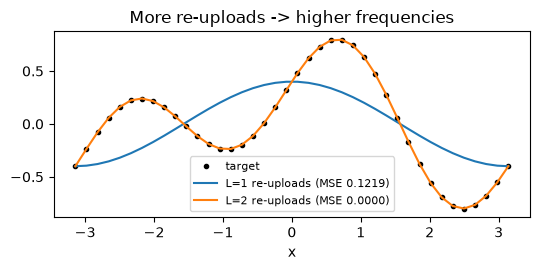

In [9]:
x_fit = np.linspace(-np.pi, np.pi, 40)
target = 0.5 * np.sin(2 * x_fit) + 0.4 * np.cos(x_fit)

def reupload_model(x, w, L):
    """1 qubit: L times [general rotation RZ RY RZ (trainable), then RY(x)], then a final trainable rotation."""
    w = w.reshape(L + 1, 3)
    psi = zero_states(len(x), 1)
    for l in range(L + 1):
        for axis, angle in zip("zyz", w[l]):
            psi = apply_1q_batch(psi, rot(axis, angle), 0, 1)
        if l < L:
            psi = apply_1q_batch(psi, rot("y", x), 0, 1)       # encode x again
    return (np.abs(psi) ** 2) @ z_signs(1, [0])

plt.figure(figsize=(5.5, 2.8)); plt.plot(x_fit, target, "k.", label="target")
for L in [1, 2]:
    best = min((minimize(lambda w: np.mean((reupload_model(x_fit, w, L) - target) ** 2),
                         rng.uniform(0, 2 * np.pi, 3 * (L + 1)), method="L-BFGS-B") for _ in range(4)),
               key=lambda r: r.fun)
    plt.plot(x_fit, reupload_model(x_fit, best.x, L), label=f"L={L} re-uploads (MSE {best.fun:.4f})")
plt.xlabel("x"); plt.legend(fontsize=8); plt.title("More re-uploads -> higher frequencies"); plt.tight_layout(); plt.show()

**What just happened?** With one encoding (L=1) the model cannot draw the $\sin(2x)$ part, so the error stays large. With two encodings (L=2) it fits almost perfectly. This is why our classifier re-uploads the data in every layer.

## 6. Train a variational classifier on make_moons

**What it is.** A binary classifier: the model output $\langle Z_0\rangle \in [-1, 1]$ becomes a probability $p = (1 + \langle Z_0\rangle)/2$ of class 1. We minimise the **binary cross-entropy** loss with the **Adam** optimiser, using parameter-shift gradients (chain rule: d loss/d angle = d loss/d output × d output/d angle).

**Data.** 100 points of scikit-learn's two interleaving half-moons, standardised, 70 for training and 30 for testing. We keep it tiny on purpose: on hardware, every training step would cost 2 × 12 parameters × 70 points = 1,680 circuit runs (times the shots for each).

In [10]:
X_all, y_all = make_moons(n_samples=100, noise=0.15, random_state=SEED)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, train_size=70, random_state=SEED, stratify=y_all)
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)

def predict_proba(X, w):
    return np.clip((1 + classifier_expval(X, w)) / 2, 1e-7, 1 - 1e-7)

def bce(p, y):
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

w = rng.normal(0, 0.5, (N_LAYERS, 4))
m, v = np.zeros_like(w), np.zeros_like(w)                     # Adam moment estimates
lr, history = 0.1, []
t0 = time.time()
for step in range(1, 121):
    p = predict_proba(X_tr, w)
    history.append(bce(p, y_tr))
    dL_dp = (p - y_tr) / (p * (1 - p)) / len(y_tr)             # derivative of BCE w.r.t. p
    dp_dw = param_shift_grad(lambda ww: classifier_expval(X_tr, ww), w) / 2   # p = (1 + <Z>)/2
    grad = dp_dw @ dL_dp                                        # chain rule, summed over points
    m = 0.9 * m + 0.1 * grad; v = 0.999 * v + 0.001 * grad ** 2  # Adam update
    w -= lr * (m / (1 - 0.9 ** step)) / (np.sqrt(v / (1 - 0.999 ** step)) + 1e-8)

acc_q_tr = np.mean((predict_proba(X_tr, w) > 0.5) == y_tr)
acc_q_te = np.mean((predict_proba(X_te, w) > 0.5) == y_te)
print(f"trained in {time.time() - t0:.1f} s;  final loss {history[-1]:.3f}")
print(f"quantum classifier accuracy: train {acc_q_tr:.2f}, test {acc_q_te:.2f}")

trained in 2.0 s;  final loss 0.168
quantum classifier accuracy: train 0.94, test 0.93


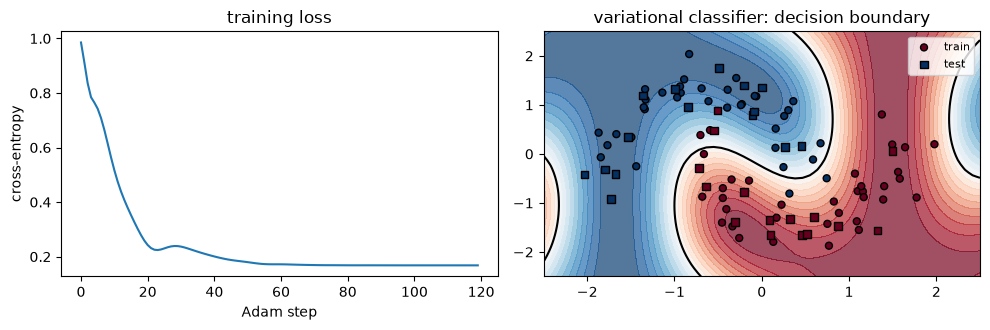

In [11]:
# Loss curve and decision boundary
gx, gy = np.meshgrid(np.linspace(-2.5, 2.5, 60), np.linspace(-2.5, 2.5, 60))
grid = np.c_[gx.ravel(), gy.ravel()]
pg = predict_proba(grid, w).reshape(gx.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(history); axes[0].set_xlabel("Adam step"); axes[0].set_ylabel("cross-entropy"); axes[0].set_title("training loss")
axes[1].contourf(gx, gy, pg, levels=20, cmap="RdBu_r", alpha=0.7)
axes[1].contour(gx, gy, pg, levels=[0.5], colors="k")
axes[1].scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="RdBu_r", edgecolor="k", s=25, label="train")
axes[1].scatter(X_te[:, 0], X_te[:, 1], c=y_te, cmap="RdBu_r", edgecolor="k", marker="s", s=30, label="test")
axes[1].set_title("variational classifier: decision boundary"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
# Honest comparison with classical models on exactly the same split
baselines = {
    "logistic regression (linear)": LogisticRegression(),
    "RBF SVM": SVC(kernel="rbf"),
    "small MLP (16 hidden units)": MLPClassifier(hidden_layer_sizes=(16,), max_iter=3000, random_state=SEED),
}
print(f"{'model':32} {'test accuracy':>13}   trainable parameters")
print(f"{'variational quantum classifier':32} {acc_q_te:13.2f}   {w.size}")
for name, model in baselines.items():
    model.fit(X_tr, y_tr)
    n_par = (sum(c.size for c in model.coefs_) + sum(b.size for b in model.intercepts_)) if hasattr(model, "coefs_") \
            else (model.coef_.size + 1 if hasattr(model, "coef_") else "support vectors: %d" % model.n_support_.sum())
    print(f"{name:32} {model.score(X_te, y_te):13.2f}   {n_par}")

model                            test accuracy   trainable parameters
variational quantum classifier            0.93   12
logistic regression (linear)              0.83   3
RBF SVM                                   0.93   support vectors: 28


small MLP (16 hidden units)               0.90   65


**What just happened?** The 12-angle quantum circuit learned a curved boundary and does far better than a straight line (logistic regression). An RBF SVM, trained in milliseconds with default settings, matches it, and a tiny MLP is close. That is the usual picture in published benchmarks too (for example Bowles, Ahmed and Schuld, "Better than classical? The subtle art of benchmarking quantum machine learning models", 2024): on small classical datasets, simple classical baselines are hard to beat.

## 7. Quantum kernels

**What it is.** A **kernel** is a similarity function $k(x, x')$ between two data points; a kernel method such as the **support vector machine (SVM)** only needs the matrix of all pairwise similarities. A **quantum kernel** (Havlíček et al., 2019; Schuld and Killoran, 2019) encodes each point as a quantum state $\lvert\phi(x)\rangle$ and uses the **fidelity** (overlap) as the similarity:

$$k(x, x') = \lvert\langle\phi(x)\vert\phi(x')\rangle\rvert^2$$

**Simple analogy.** Two songs are "similar" if, after both are played through the same strange echo chamber (the quantum feature map), the recordings overlap a lot. The hope is that the quantum echo chamber reveals patterns a classical one cannot.

**How it works.**
1. Choose a feature-map circuit. We use the Havlíček-style "ZZ feature map" on 2 qubits: H gates, RZ($2x_i$), and an entangling term that depends on the product $(\pi - x_0)(\pi - x_1)$, repeated twice.
2. Compute the kernel matrix for all pairs of training points (and test-vs-training points).
3. Give the matrix to `SVC(kernel="precomputed")`. The SVM itself is fully classical.

On hardware, each entry is estimated with the "compute-uncompute" circuit $U(x')^\dagger U(x)$: the probability of measuring all zeros equals the fidelity. That needs about $N^2/2$ circuits for N training points, each with many shots.

In [13]:
def zz_feature_map(X, reps=2):
    """Havlicek-style ZZ feature map on 2 qubits for each row of X. Returns states (B, 4)."""
    psi = zero_states(len(X), 2)
    Hb = np.broadcast_to(H, (len(X), 2, 2))
    for _ in range(reps):
        psi = apply_1q_batch(psi, Hb, 0, 2); psi = apply_1q_batch(psi, Hb, 1, 2)
        psi = apply_1q_batch(psi, rot("z", 2 * X[:, 0]), 0, 2)
        psi = apply_1q_batch(psi, rot("z", 2 * X[:, 1]), 1, 2)
        psi = cnot_batch(psi, 0, 1, 2)                                        # entangling ZZ term:
        psi = apply_1q_batch(psi, rot("z", 2 * (np.pi - X[:, 0]) * (np.pi - X[:, 1])), 1, 2)
        psi = cnot_batch(psi, 0, 1, 2)
    return psi

def fidelity_kernel(A, B):
    SA, SB = zz_feature_map(A), zz_feature_map(B)
    return np.abs(SA.conj() @ SB.T) ** 2        # |<phi(a)|phi(b)>|^2 for every pair

# The feature map is sensitive to the scale of the inputs: we squeeze the standardised features
SCALE = 0.5
K_tr = fidelity_kernel(SCALE * X_tr, SCALE * X_tr)
K_te = fidelity_kernel(SCALE * X_te, SCALE * X_tr)
print("kernel matrix shape:", K_tr.shape, " diagonal is all 1:", np.allclose(np.diag(K_tr), 1))

qsvm = SVC(kernel="precomputed").fit(K_tr, y_tr)
rbf = SVC(kernel="rbf").fit(X_tr, y_tr)
print(f"quantum-kernel SVM test accuracy (SCALE={SCALE}): {qsvm.score(K_te, y_te):.2f}")
print(f"RBF-kernel SVM test accuracy:                  {rbf.score(X_te, y_te):.2f}")

kernel matrix shape: (70, 70)  diagonal is all 1: True
quantum-kernel SVM test accuracy (SCALE=0.5): 0.73
RBF-kernel SVM test accuracy:                  0.93


In [14]:
# The input scale works like the bandwidth of an RBF kernel: choose it by cross-validation
# on the TRAINING set only (never on the test set), then score once on the test set.
from sklearn.model_selection import cross_val_score
cv_scores = {}
for sc in [0.1, 0.25, 0.5, 1.0, 2.0]:
    K = fidelity_kernel(sc * X_tr, sc * X_tr)
    cv_scores[sc] = cross_val_score(SVC(kernel="precomputed"), K, y_tr, cv=5).mean()
    print(f"SCALE={sc:<5} 5-fold CV accuracy on the training set: {cv_scores[sc]:.2f}")
best_sc = max(cv_scores, key=cv_scores.get)
qsvm_best = SVC(kernel="precomputed").fit(fidelity_kernel(best_sc * X_tr, best_sc * X_tr), y_tr)
acc_qk = qsvm_best.score(fidelity_kernel(best_sc * X_te, best_sc * X_tr), y_te)
print(f"chosen SCALE={best_sc}: quantum-kernel SVM test accuracy {acc_qk:.2f}  (RBF SVM: {rbf.score(X_te, y_te):.2f})")

SCALE=0.1   5-fold CV accuracy on the training set: 0.77
SCALE=0.25  5-fold CV accuracy on the training set: 0.73
SCALE=0.5   5-fold CV accuracy on the training set: 0.73
SCALE=1.0   5-fold CV accuracy on the training set: 0.64
SCALE=2.0   5-fold CV accuracy on the training set: 0.41
chosen SCALE=0.1: quantum-kernel SVM test accuracy 0.77  (RBF SVM: 0.93)


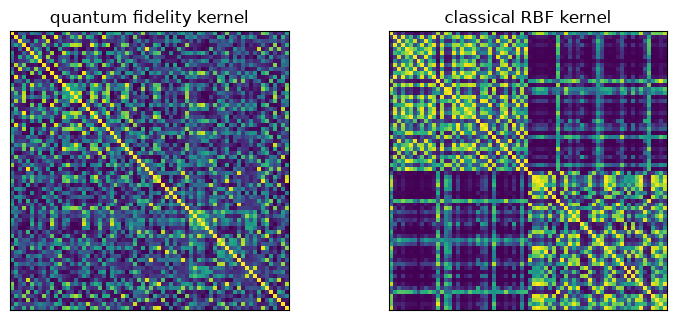

kernel entry k(x0, x1) exact 0.231;  five 1000-shot estimates: [0.245 0.243 0.251 0.21  0.23 ]
circuits needed for the training kernel on hardware: 2,415 (x shots each)


In [15]:
# Look at the kernel matrices (points sorted by class) and check one entry with shots
order = np.argsort(y_tr)
from sklearn.metrics.pairwise import rbf_kernel
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
axes[0].imshow(K_tr[np.ix_(order, order)], cmap="viridis"); axes[0].set_title("quantum fidelity kernel")
axes[1].imshow(rbf_kernel(X_tr, gamma=0.5)[np.ix_(order, order)], cmap="viridis"); axes[1].set_title("classical RBF kernel")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

# On hardware: entry (0, 1) estimated from the all-zeros probability with 1000 shots
true_k = K_tr[0, 1]
est = rng.binomial(1000, true_k, size=5) / 1000
print(f"kernel entry k(x0, x1) exact {true_k:.3f};  five 1000-shot estimates: {est}")
print(f"circuits needed for the training kernel on hardware: {len(X_tr) * (len(X_tr) - 1) // 2:,} (x shots each)")

**What just happened?** The quantum-kernel SVM works, but its accuracy depends strongly on the input scale, which acts like the bandwidth of an RBF kernel and must be tuned (by cross-validation on the training data, as above). Even after tuning it does not beat the plain RBF SVM on this data. In the kernel pictures, both kernels show two blocks (points of the same class are more similar to each other). Estimating every entry with shots adds noise, and the number of circuits grows with the square of the training-set size.

**When quantum kernels could make sense.** There are proofs of advantage for specially constructed datasets (for example ones built on the discrete-logarithm problem, Liu, Arunachalam and Temme, 2021). For ordinary data there is no evidence of advantage, and with many qubits most fidelity kernels suffer **exponential concentration**: all off-diagonal entries become nearly 0, the kernel matrix looks like the identity, and the model cannot generalise (Thanasilp et al., 2024).

## 8. Hybrid quantum-classical models

**What it is.** A **hybrid model** puts a quantum circuit inside an otherwise classical model, usually as one layer. For example, a classical CNN shrinks an image to 4 numbers, a 4-qubit circuit transforms them, and a classical linear layer makes the final prediction. Everything is trained end to end: the classical parts by backpropagation, the quantum layer by parameter shift (or by simulator backprop).

**Simple analogy.** A relay race: classical runners do most of the distance, and a quantum runner does one short leg in the middle.

```mermaid
flowchart LR
    I[input image] --> C1[classical CNN<br/>feature extractor]
    C1 --> R[4 numbers]
    R --> Q[4-qubit<br/>variational circuit]
    Q --> E[4 expectation values]
    E --> C2[classical linear layer]
    C2 --> Y[prediction]
```

**Tools.** PennyLane connects circuits to PyTorch and JAX; Qiskit Machine Learning connects to PyTorch; TensorFlow Quantum exists but is less active. A sketch with PennyLane and PyTorch (not run here, because PyTorch is not used in this track):

```python
import pennylane as qml, torch
dev = qml.device("default.qubit", wires=4)

@qml.qnode(dev, interface="torch")
def circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(4))
    qml.StronglyEntanglingLayers(weights, wires=range(4))
    return [qml.expval(qml.PauliZ(i)) for i in range(4)]

qlayer = qml.qnn.TorchLayer(circuit, {"weights": (2, 4, 3)})
model = torch.nn.Sequential(torch.nn.Linear(16, 4), qlayer, torch.nn.Linear(4, 2))
```

**Honest caveat.** In many published hybrid models, removing the quantum layer (or replacing it with a small classical layer) gives similar accuracy. Always run that **ablation** (see [24_Research_Methods/02_experiment_design_for_ml.ipynb](../24_Research_Methods/02_experiment_design_for_ml.ipynb)).

## 9. Quantum reinforcement learning and quantum GANs (conceptual)

**Quantum reinforcement learning (QRL).** In [reinforcement learning](../11_Reinforcement_Learning/01_rl_fundamentals.ipynb) an agent learns a policy from rewards. QRL research has two main directions:
- **Variational policies or Q-functions:** replace the policy network or Q-network with a PQC (Jerbi et al. 2021; Skolik et al. 2022). They work on small toy environments such as CartPole, with no demonstrated advantage over classical networks of similar size.
- **Quantum speedups for parts of RL:** for example Grover-style search or amplitude estimation inside planning. These need error-corrected hardware.

**Quantum GANs (QGANs).** A **generative adversarial network** has a generator that makes fake samples and a discriminator that tries to spot them. In a QGAN the generator (and sometimes the discriminator) is a PQC (Lloyd and Weedbrook 2018; Dallaire-Demers and Killoran 2018). A natural fit: a quantum circuit *naturally* produces random samples (its measurement results), so it can act as a "Born machine" that learns a probability distribution. Demonstrations so far are small (a few qubits, simple distributions such as a log-normal curve for option pricing).

**Simple analogy.** Both are like replacing one musician in a band with a new kind of instrument. It is interesting to hear, but there is not yet any evidence that the band sounds better.

| Idea | Status as of late 2026 (stated generally) |
|---|---|
| PQC policy for RL | works on toy environments; no practical advantage shown |
| QGAN / quantum Born machine | small demonstrations; trainability issues like other PQCs |
| Quantum speedup for RL planning | theoretical; needs fault-tolerant hardware |

## 10. The limits of QML today

### 10.1 Barren plateaus

**What it is.** A **barren plateau** (McClean et al., 2018) is a training landscape that is almost perfectly flat: for randomly initialised, deep enough circuits, the gradients are close to zero everywhere, and their **variance shrinks exponentially with the number of qubits**. Estimating an exponentially small gradient needs exponentially many shots, so training stalls.

**Simple analogy.** Looking for the lowest point of a desert that is flat to within a millimetre, in a sandstorm (shot noise). You cannot tell which way is downhill.

**Small experiment.** For n = 2 ... 9 qubits we build random circuits (layers of RY and RZ on every qubit plus a ladder of CZ gates, depth 4n), pick 150 random initialisations, and compute the parameter-shift gradient of $\langle Z_0 Z_1\rangle$ with respect to one angle in the middle of the circuit. We plot the variance of that gradient. For comparison we also do the same with a **shallow** circuit (2 layers).

In [16]:
def random_circuit_grad(n, layers, B=150, seed=0):
    """Parameter-shift gradient of <Z0 Z1> w.r.t. one middle angle, for B random circuits at once."""
    r = np.random.default_rng(seed)
    angles = r.uniform(0, 2 * np.pi, (layers, n, 2, B))
    cz_ladder = z_signs(n, []).copy()
    idx = np.arange(2 ** n); bit = lambda q: (idx >> (n - 1 - q)) & 1
    for q in range(n - 1):
        cz_ladder *= 1 - 2 * (bit(q) & bit(q + 1))             # CZ = minus sign when both qubits are 1
    obs = z_signs(n, [0, 1])
    def run(shift):
        psi = zero_states(B, n)
        for l in range(layers):
            for q in range(n):
                s = shift if (l == layers // 2 and q == 0) else 0.0
                psi = apply_1q_batch(psi, rot("y", angles[l, q, 0] + s), q, n)
                psi = apply_1q_batch(psi, rot("z", angles[l, q, 1]), q, n)
            psi = psi * cz_ladder
        return (np.abs(psi) ** 2) @ obs
    return (run(np.pi / 2) - run(-np.pi / 2)) / 2

t0 = time.time()
ns = list(range(2, 10))
var_deep = [random_circuit_grad(n, 4 * n).var() for n in ns]
var_shallow = [random_circuit_grad(n, 2).var() for n in ns]
print(f"done in {time.time() - t0:.1f} s")
for n, vd, vs in zip(ns, var_deep, var_shallow):
    print(f"n={n}:  Var[grad] deep {vd:.5f}   shallow {vs:.5f}   (1/2^n = {1/2**n:.5f})")

done in 1.9 s
n=2:  Var[grad] deep 0.12109   shallow 0.19244   (1/2^n = 0.25000)
n=3:  Var[grad] deep 0.05431   shallow 0.17083   (1/2^n = 0.12500)
n=4:  Var[grad] deep 0.03260   shallow 0.18423   (1/2^n = 0.06250)
n=5:  Var[grad] deep 0.01370   shallow 0.17484   (1/2^n = 0.03125)
n=6:  Var[grad] deep 0.01258   shallow 0.16861   (1/2^n = 0.01562)
n=7:  Var[grad] deep 0.00611   shallow 0.15142   (1/2^n = 0.00781)
n=8:  Var[grad] deep 0.00347   shallow 0.14268   (1/2^n = 0.00391)
n=9:  Var[grad] deep 0.00210   shallow 0.15345   (1/2^n = 0.00195)


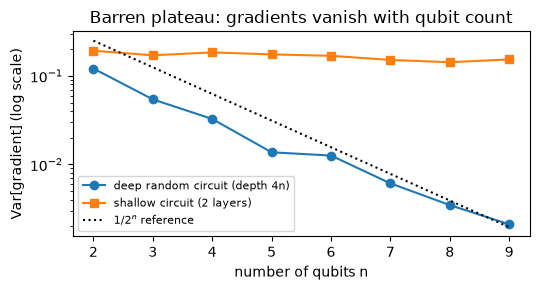

In [17]:
plt.figure(figsize=(5.5, 3))
plt.semilogy(ns, var_deep, "o-", label="deep random circuit (depth 4n)")
plt.semilogy(ns, var_shallow, "s-", label="shallow circuit (2 layers)")
plt.semilogy(ns, [1 / 2 ** n for n in ns], "k:", label=r"$1/2^n$ reference")
plt.xlabel("number of qubits n"); plt.ylabel("Var[gradient] (log scale)")
plt.title("Barren plateau: gradients vanish with qubit count"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** For the deep random circuits, the gradient variance falls roughly like $1/2^n$, a straight line on the log plot: each extra qubit halves it. At 50 qubits that would be about $10^{-15}$, far below what any realistic number of shots can resolve. The shallow circuit with a **local** cost (one that looks at only two qubits) keeps healthy gradients here, which matches later theory (Cerezo et al., 2021). The catch: shallow, local circuits are often also easy to simulate classically, so escaping the plateau can remove the reason to use a quantum computer. As of late 2026 this "trainable implies classically simulable?" question is an active research topic.

**Ways people fight barren plateaus:** shallow or problem-inspired circuits, local cost functions, smart initialisation (start near the identity), layer-wise training, and symmetry-aware ("geometric") circuit design. None is a universal fix.

### 10.2 Noise and the NISQ reality

Today's devices are **noisy**: every gate has a small error rate (typically between about $10^{-4}$ and $10^{-2}$ for the best 1- and 2-qubit gates, depending on the hardware), and qubits lose their state over time (**decoherence**). Noise shrinks expectation values toward 0, which also flattens gradients (**noise-induced barren plateaus**, Wang et al. 2021). Error mitigation helps but costs extra shots, and full error correction needs many physical qubits per logical qubit (notebook 04 shows a noise demo and explains both).

### 10.3 The data-loading bottleneck

| Step | Cost | Why it hurts QML on classical data |
|---|---|---|
| Load N classical numbers into amplitudes | about N gates in general (or a "qRAM" that does not exist at scale) | wipes out exponential speedups that assume the data is already loaded |
| Read results out | one bitstring per shot; estimating a value to precision $\epsilon$ needs about $1/\epsilon^2$ shots | you cannot read the $2^n$ amplitudes |
| Gradients | 2 circuits per parameter per data point (parameter shift) | training on large datasets is very slow; mini-batches of millions of points are not realistic |
| Clock speed | gates take nanoseconds to microseconds, plus readout and classical round-trips | GPUs do about $10^{14}$ or more operations per second |

### 10.4 Dequantization

**What it is.** **Dequantization** means finding a *classical* algorithm that matches a claimed quantum speedup, once you give the classical algorithm the same kind of data access that the quantum algorithm assumed. Ewin Tang (2018, published at STOC 2019) gave a classical algorithm for recommendation systems that runs only polynomially slower than the quantum algorithm of Kerenidis and Prakash, removing its exponential advantage. Similar "quantum-inspired" classical algorithms followed for low-rank linear systems, PCA and other QML proposals built on HHL-style linear algebra.

**Simple analogy.** Someone claims a teleporter beats every car. Then you notice the teleporter needs the destination pre-loaded into a magic map that nobody can build. Give a car the same magic map and it gets there almost as fast.

### 10.5 Honest takeaway

| Claim you will hear | Reality (as of late 2026) |
|---|---|
| "Quantum ML will train neural networks exponentially faster" | no evidence; data loading, readout and gradients cost too much |
| "Quantum kernels beat classical kernels" | only on specially constructed problems; on real data classical kernels match or beat them |
| "Variational circuits are more expressive" | they can be expressive, but expressive ones tend to have barren plateaus |
| "QML works on today's hardware" | small demonstrations work; none beats strong classical baselines on a practical task |
| "So QML is useless" | also wrong: it is a serious research field, quantum *data* (QQ) is promising, and ML is already very useful *for* quantum computing (notebook 04) |

The practical advice for an AI engineer: learn the ideas, be able to evaluate claims (ask for the classical baseline, the qubit count, the shot budget and the noise model), and do not use QML in production for classical data today.

## 11. Recap (cheat sheet)

| Concept | One-line meaning | Where in this notebook |
|---|---|---|
| CC / CQ / QC / QQ | data type × algorithm type | section 1 |
| Basis / angle / amplitude encoding | bits as basis states / features as angles / vector as amplitudes | section 2 |
| Data re-uploading | encode the input repeatedly; more repeats = higher Fourier frequencies | section 5 |
| Variational circuit (PQC, QNN) | encoding + trainable rotations + measured expectation value | sections 3, 6 |
| Parameter-shift rule | exact gradient from two runs shifted by $\pm\pi/2$ | section 4 |
| Variational classifier | p = (1 + ⟨Z⟩)/2, trained with cross-entropy and Adam | section 6 |
| Quantum (fidelity) kernel | $k(x,x') = \lvert\langle\phi(x)\vert\phi(x')\rangle\rvert^2$, used by a classical SVM | section 7 |
| Hybrid model | quantum circuit as one layer in a classical model | section 8 |
| QRL / QGAN | PQC as policy / generator; toy-scale so far | section 9 |
| Barren plateau | gradient variance shrinks exponentially with qubits | section 10.1 |
| Data-loading bottleneck | getting classical data in and results out costs too much | section 10.3 |
| Dequantization | classical algorithms matching claimed quantum speedups | section 10.4 |

## 12. Interview questions

1. **What are the four CC/CQ/QC/QQ categories?** Data (classical or quantum) × processing device (classical or quantum). Most QML papers are CQ; ML for quantum devices is QC.
2. **Compare angle and amplitude encoding.** Angle: one feature per qubit, cheap to prepare. Amplitude: $2^n$ features in n qubits, but preparing the state generally needs about $2^n$ gates.
3. **What is the parameter-shift rule and why not use finite differences?** The exact derivative of an expectation value from two runs at $\theta\pm\pi/2$. Finite differences with small steps are swamped by shot noise.
4. **What does data re-uploading do?** It repeats the encoding; each repeat raises the highest Fourier frequency the model can represent.
5. **How do you turn a PQC into a classifier?** Map an expectation value in [−1, 1] to a probability, e.g. $p = (1+\langle Z\rangle)/2$, and train with cross-entropy.
6. **How is a quantum kernel used with an SVM?** Compute the fidelity matrix on the quantum device (or simulator) and give it to a classical SVM as a precomputed kernel.
7. **What is a barren plateau and how do you mitigate it?** Exponentially vanishing gradients in random deep circuits; use shallow/structured circuits, local costs and careful initialisation.
8. **What is dequantization?** A classical algorithm, with comparable data access (sampling assumptions), that matches a claimed quantum speedup; e.g. Tang's recommendation algorithm.
9. **Why is the data-loading bottleneck important?** Many exponential QML speedups assume the data is already in quantum memory; loading it costs time linear in the data size.
10. **A paper reports a QML model with 95% accuracy. What do you ask?** Classical baselines on the same split, number of qubits and parameters, simulator or hardware, shots and noise, and whether removing the quantum part changes the result.

## 13. Further reading

- M. Schuld and F. Petruccione, *Machine Learning with Quantum Computers*, Springer, 2nd ed. 2021. The standard textbook for this notebook.
- V. Havlíček et al., "Supervised learning with quantum-enhanced feature spaces", *Nature* 567 (2019), arXiv:1804.11326.
- M. Schuld and N. Killoran, "Quantum machine learning in feature Hilbert spaces", *Physical Review Letters* (2019).
- J. R. McClean et al., "Barren plateaus in quantum neural network training landscapes", *Nature Communications* 9 (2018), arXiv:1803.11173.
- M. Cerezo et al., "Cost function dependent barren plateaus in shallow parametrized quantum circuits", *Nature Communications* (2021).
- K. Mitarai et al., "Quantum circuit learning", *Physical Review A* (2018); M. Schuld et al., "Evaluating analytic gradients on quantum hardware", *Physical Review A* (2019).
- A. Pérez-Salinas et al., "Data re-uploading for a universal quantum classifier", *Quantum* (2020); M. Schuld, R. Sweke and J. J. Meyer, "Effect of data encoding on the expressive power of variational quantum machine learning models", *Physical Review A* (2021).
- E. Tang, "A quantum-inspired classical algorithm for recommendation systems", STOC 2019, arXiv:1807.04271.
- S. Thanasilp et al., "Exponential concentration in quantum kernel methods", *Nature Communications* (2024).
- J. Bowles, S. Ahmed and M. Schuld, "Better than classical? The subtle art of benchmarking quantum machine learning models" (2024).
- J. Preskill, "Quantum Computing in the NISQ era and beyond", *Quantum* 2, 79 (2018), arXiv:1801.00862.
- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 2010.
- PennyLane QML demos (pennylane.ai/qml): "Variational classifier", "Data re-uploading classifier", "Kernel-based training", "Barren plateaus". Qiskit Machine Learning documentation (tutorials on QSVC and quantum neural networks).

## Where to go next

- [04_quantum_ai_tools_hardware_and_industry.ipynb](04_quantum_ai_tools_hardware_and_industry.ipynb): the same classifier in Qiskit and PennyLane, noise, error correction, AI for quantum, and industry use cases.
- Classical counterparts: [SVMs and kernels](../03_Machine_Learning/01_supervised/05_svm.ipynb), [neural network fundamentals](../05_Deep_Learning/01_neural_network_fundamentals.ipynb), [optimizers](../05_Deep_Learning/02_optimizers.ipynb).